In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

In [ ]:
data = []
labels = []

path = r"C:\Users\ritik\Desktop\plant disese\PlantVillage"

max_images = 150 

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    # skip if not folder
    if not os.path.isdir(folder_path):
        continue

    count = 0   

    for img_name in os.listdir(folder_path):

        if count >= max_images:   
            break

        # only process image files
        if not img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue

        img_path = os.path.join(folder_path, img_name)

        img = cv2.imread(img_path)

        # skip broken images
        if img is None:
            continue

        img = cv2.resize(img, (32, 32))

        data.append(img.flatten())
        labels.append(folder)

        count += 1    
        

In [ ]:
X = np.array(data)
y = np.array(labels)

print("Dataset Loaded ")
print("Total samples:", len(X))
print("Feature shape:", X.shape)

Dataset Loaded ✅
Total samples: 2250
Feature shape: (2250, 3072)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data split done")

Data split done ✅


In [6]:
max_images = 200  # per class
count = 0

for img_name in os.listdir(folder_path):
    if count >= max_images:
        break

In [ ]:
from sklearn.svm import LinearSVC
svm = LinearSVC()   # fast model

print("Training SVM...")
svm.fit(X_train, y_train)

print("Training complete ")


Training SVM... ⏳
Training complete ✅


c:\Users\ritik\Desktop\plant disese\venv\lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [8]:
accuracy = svm.score(X_test, y_test)
print("SVM Accuracy:", accuracy)


SVM Accuracy: 0.4266666666666667


Predicted class: Potato___Late_blight


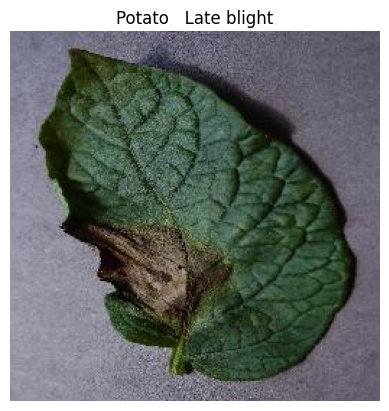

In [ ]:
img_path = r"C:\Users\ritik\Downloads\archive (1)\PlantVillage\Potato___Late_blight\fc9b06c8-7c63-445d-9858-a5a0c7be719b___RS_LB 3273.JPG"

img = cv2.imread(img_path)

if img is None:
    print("Image not found ")
else:
    img_resized = cv2.resize(img, (32, 32))
    img_flat = img_resized.flatten().reshape(1, -1)

    prediction = svm.predict(img_flat)
    predicted_class = prediction[0]

    print("Predicted class:", predicted_class)

    # display image
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(predicted_class.replace("_", " "))
    plt.show()